# α-BaCu₂Se₂ multi-objective Bayesian optimization with Ax

Unlike notebook 3 (which combines purity and crystallinity into one hand-weighted score), here we treat **phase purity** and **normalized crystallinity** as two separate objectives. Ax fits an independent GP per metric and finds the **Pareto front** — the set of films where improving one objective would worsen the other — then suggests conditions that maximize hypervolume (qNEHVI). The 21 observed films are attached as completed trials, then Ax proposes the next synthesis conditions.

In [7]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from xrd_bo_optimization_tf.bayesian_opt import prepare_optimization_data
from xrd_bo_optimization_tf.config import GENERATED_XRD_METRICS_CSV, NOMAD_SYNTHESIS_CSV

metrics = pd.read_csv(GENERATED_XRD_METRICS_CSV)
synthesis = pd.read_csv(NOMAD_SYNTHESIS_CSV)
df_bo = prepare_optimization_data(metrics, synthesis=synthesis, include_pulse=True)
BO_PARAMS = list(df_bo.attrs["parameter_columns"])

print(f"Optimization parameters ({len(BO_PARAMS)}): {BO_PARAMS}")
print(f"Complete observations: {len(df_bo)} films, objective {df_bo['objective'].min():.2f}–{df_bo['objective'].max():.2f}")
df_bo[["sample_id", *BO_PARAMS, "objective"]].head()

Optimization parameters (7): ['spin_speed_rpm', 'soft_bake_temp_c', 'hard_bake_temp_c', 'selenization_temp_c', 'selenization_time_s', 'se_pulse_on_ms', 'se_pulse_off_ms']
Complete observations: 21 films, objective 0.57–1.00


,sample_id,spin_speed_rpm,soft_bake_temp_c,hard_bake_temp_c,selenization_temp_c,selenization_time_s,se_pulse_on_ms,se_pulse_off_ms,objective
0,260429A11,2000.0,100.0,250.0,520.0,600.0,500.0,2700.0,0.566310
1,260429A12,2000.0,100.0,250.0,520.0,600.0,500.0,2700.0,0.730046
3,260429A3,2000.0,100.0,250.0,560.0,1800.0,500.0,2700.0,0.877812
4,260429B1,2000.0,100.0,250.0,520.0,1200.0,500.0,2700.0,0.811654
5,260429B2,2000.0,100.0,250.0,540.0,1800.0,500.0,2700.0,1.000000


In [8]:
# Create the Ax experiment: 7 range parameters, TWO objectives to maximize.
# Objective thresholds define the reference point for hypervolume (worst acceptable).
from ax.service.ax_client import AxClient, ObjectiveProperties

ax_client = AxClient(verbose_logging=False)
ax_client.create_experiment(
    name="bacuse2_xrd_moo",
    parameters=[
        {
            "name": name,
            "type": "range",
            "bounds": [float(df_bo[name].min()), float(df_bo[name].max())],
            "value_type": "float",
        }
        for name in BO_PARAMS
    ],
    objectives={
        "phase_purity": ObjectiveProperties(
            minimize=False, threshold=float(df_bo["phase_purity"].min())
        ),
        "crystallinity_norm": ObjectiveProperties(minimize=False, threshold=0.0),
    },
)
print(f"Ax multi-objective experiment over {len(BO_PARAMS)} parameters")
print("Objectives: maximize phase_purity and crystallinity_norm")

/tmp/ipykernel_3989603/1069196043.py:5: DeprecationWarning: The `AxClient` class is deprecated and will be removed in Ax 1.4.0. Please migrate to the modern Ax API / `Client` class, found under ax/api. For example usage, check out the tutorials at https://ax.dev 
  ax_client = AxClient(verbose_logging=False)
[INFO 10-23 16:02:05] ax.generation_strategy.dispatch_utils: Using Generators.BOTORCH_MODULAR since there is at least one ordered parameter and there are no unordered categorical parameters.
[INFO 10-23 16:02:05] ax.generation_strategy.dispatch_utils: Using Bayesian Optimization generation strategy: GenerationStrategy(name='GenerationStep_0_Sobol+GenerationStep_1_BoTorch', nodes=[GenerationNode(name='GenerationStep_0_Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, generator_key_override=None)], transition_criteria=[MinTrials(transition_to='GenerationStep_1_BoTorch'), MinTrials(transition_to='GenerationStep_1_BoTorch')], suggested_experiment_status=ExperimentStatus.INIT

Ax multi-objective experiment over 7 parameters
Objectives: maximize phase_purity and crystallinity_norm


In [9]:
# Attach each observed film as a completed trial with BOTH objective values.
for _, row in df_bo.iterrows():
    parameters = {name: float(row[name]) for name in BO_PARAMS}
    _, trial_index = ax_client.attach_trial(parameters=parameters)
    ax_client.complete_trial(
        trial_index=trial_index,
        raw_data={
            "phase_purity": (float(row["phase_purity"]), float("nan")),
            "crystallinity_norm": (float(row["crystallinity_norm"]), float("nan")),
        },
    )

print(f"Attached {len(df_bo)} completed trials")
ax_client.get_trials_data_frame()[
    ["trial_index", "trial_status", "phase_purity", "crystallinity_norm"]
].head()

Attached 21 completed trials


,trial_index,trial_status,phase_purity,crystallinity_norm
0,0,COMPLETED,0.809015,0.000000
1,1,COMPLETED,1.000000,0.100153
2,2,COMPLETED,1.000000,0.592707
3,3,COMPLETED,1.000000,0.372181
4,4,COMPLETED,1.000000,1.000000


In [10]:
# Ask Ax for candidate synthesis conditions along the Pareto front (qNEHVI).
N_SUGGESTIONS = 5
ax_suggestions = []
for _ in range(N_SUGGESTIONS):
    parameters, trial_index = ax_client.get_next_trial()
    ax_suggestions.append(parameters)
    ax_client.abandon_trial(trial_index=trial_index)  # placeholder, not observed

df_ax = pd.DataFrame(ax_suggestions).round(1)
df_ax.insert(0, "rank", range(1, len(df_ax) + 1))
print("Ax-suggested next conditions (Pareto-optimal candidates):")
df_ax

Ax-suggested next conditions (Pareto-optimal candidates):


,rank,spin_speed_rpm,soft_bake_temp_c,hard_bake_temp_c,selenization_temp_c,selenization_time_s,se_pulse_on_ms,se_pulse_off_ms
0,1,1916.0,183.0,247.4,539.2,1790.8,601.1,2598.8
1,2,2000.0,100.0,250.0,543.5,1800.0,658.7,2787.4
2,3,2000.0,100.0,250.0,536.8,1800.0,399.0,2527.6
3,4,1842.5,100.0,238.4,537.7,1800.0,595.5,2659.3
4,5,2000.0,196.8,237.6,544.6,1800.0,434.2,2636.0


In [ ]:
# Save the Ax multi-objective suggestions for the report and later use.
from xrd_bo_optimization_tf.config import RESULTS_DATA_DIR

ax_suggestions_path = RESULTS_DATA_DIR / "bacuse2_ax_moo_suggestions.csv"
df_ax.to_csv(ax_suggestions_path, index=False)
print(f"Saved Ax MOO suggestions to {ax_suggestions_path}")

In [12]:
# Observed Pareto front: films where neither objective can improve without hurting the other.
pareto = ax_client.get_pareto_optimal_parameters()
pareto_rows = []
for trial_index, (params, (means, _covs)) in pareto.items():
    pareto_rows.append(
        {"trial_index": trial_index, "phase_purity": means["phase_purity"],
         "crystallinity_norm": means["crystallinity_norm"], **params}
    )
df_pareto = pd.DataFrame(pareto_rows).sort_values("phase_purity")
print(f"Pareto-optimal films: {len(df_pareto)} (values are GP model estimates)")
df_pareto[["trial_index", "phase_purity", "crystallinity_norm", *BO_PARAMS]].round(3)

Pareto-optimal films: 2 (values are GP model estimates)


,trial_index,phase_purity,crystallinity_norm,spin_speed_rpm,soft_bake_temp_c,hard_bake_temp_c,selenization_temp_c,selenization_time_s,se_pulse_on_ms,se_pulse_off_ms
0,4,0.998,0.968,2000.0,100.0,250.0,540.0,1800.0,500.0,2700.0
1,15,0.999,0.489,1500.0,100.0,250.0,550.0,1200.0,500.0,2700.0


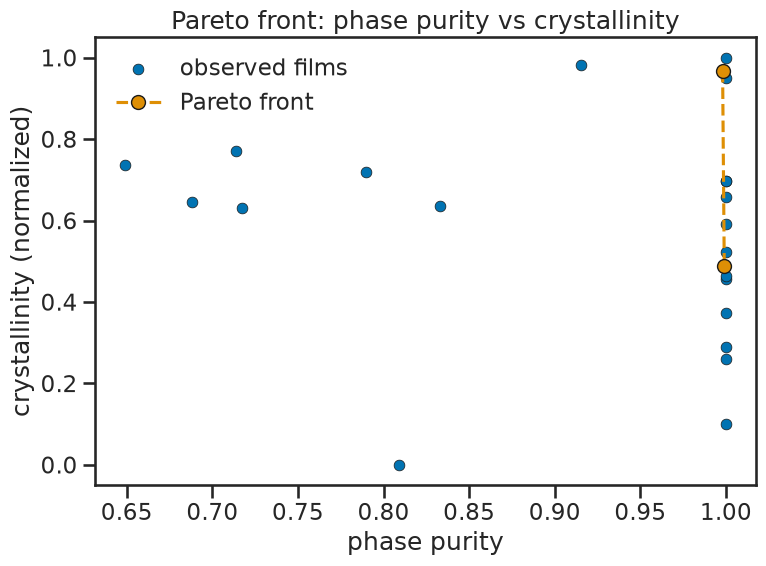

In [14]:
# Pareto front plot: crystallinity vs phase purity, Pareto films highlighted.
import matplotlib.pyplot as plt

import xrd_bo_optimization_tf.plotting as plotting  # applies the colorblind theme

figure, axis = plt.subplots(figsize=(8, 6))
axis.scatter(
    df_bo["phase_purity"], df_bo["crystallinity_norm"],
    s=60, edgecolor="k", linewidth=0.5, label="observed films", zorder=2,
)
axis.plot(
    df_pareto["phase_purity"], df_pareto["crystallinity_norm"],
    "o--", color=plotting.COLOR_IMPURITY, markersize=10,
    markeredgecolor="k", label="Pareto front", zorder=3,
)
axis.set_xlabel("phase purity")
axis.set_ylabel("crystallinity (normalized)")
axis.set_title("Pareto front: phase purity vs crystallinity")
axis.legend(frameon=False)
figure.tight_layout()
figure.savefig(
    plotting.FIGURES_DIR / "bacuse2_ax_pareto_front.png", dpi=150, bbox_inches="tight"
)
plt.show()

In [15]:
# Compare Ax (multi-objective) suggestions vs skopt (weighted single-objective) from notebook 3.
from xrd_bo_optimization_tf.config import RESULTS_DATA_DIR

skopt_path = RESULTS_DATA_DIR / "bacuse2_bo_suggestions.csv"
if skopt_path.is_file():
    df_skopt = pd.read_csv(skopt_path)
    common = ["rank", *BO_PARAMS]
    comparison = pd.concat(
        {
            "Ax (MOO)": df_ax.reindex(columns=common),
            "skopt (weighted)": df_skopt.reindex(columns=common),
        },
        axis=0,
    )
    print("Note: Ax maximizes purity AND crystallinity separately (Pareto);")
    print("skopt maximizes the single weighted objective. Suggested conditions:")
    display(comparison.round(1))
else:
    print(f"skopt suggestions not found at {skopt_path}; run notebook 3 first")

Note: Ax maximizes purity AND crystallinity separately (Pareto);
skopt maximizes the single weighted objective. Suggested conditions:


rank  spin_speed_rpm  soft_bake_temp_c  hard_bake_temp_c  \
Ax (MOO)         0     1          1916.0             183.0             247.4   
                 1     2          2000.0             100.0             250.0   
                 2     3          2000.0             100.0             250.0   
                 3     4          1842.5             100.0             238.4   
                 4     5          2000.0             196.8             237.6   
skopt (weighted) 0     1          1512.0             170.5             248.2   
                 1     2          1846.7             185.7             245.0   
                 2     3          1902.6             221.3             244.9   
                 3     4          1603.0             152.6             242.6   
                 4     5          1898.5             109.9             239.3   

                    selenization_temp_c  selenization_time_s  se_pulse_on_ms  \
Ax (MOO)         0                539.2               1790.8           601.1   
                 1                543.5               1800.0           658.7   
                 2                536.8               1800.0           399.0   
                 3                537.7               1800.0           595.5   
                 4                544.6               1800.0           434.2   
skopt (weighted) 0                540.1               1371.5           501.4   
                 1                540.3               1800.0           504.0   
                 2                539.5               1800.0           518.8   
                 3                538.4               1800.0           498.9   
                 4                540.5               1800.0           510.4   

                    se_pulse_off_ms  
Ax (MOO)         0           2598.8  
                 1           2787.4  
                 2           2527.6  
                 3           2659.3  
                 4           2636.0  
skopt (weighted) 0           2397.9  
                 1           2856.7  
                 2           2848.1  
                 3           2253.8  
                 4           2281.6